# Experimento: modelo explicativo OLS con selección por RFE — TP3 (Grupo 3)

Segundo modelo de caja de cristal, **independiente del Ridge**. Mismo dataset y misma matriz de diseño (las 8 familias,
con curvas spline, interacciones e indicadores de faltante), pero:

- **Estimador:** regresión lineal **sin penalización** (OLS). No hay α ni encogimiento.
- **Selección:** Recursive Feature Elimination. En cada paso se reentrena y sale la **variable** (con todas sus columnas)
  de menor peso = desvío de su aporte Σβx en el entrenamiento (°C). Un solo orden para los pliegues de elección 1–2.
- **Cuántas quedan:** el conjunto más chico que, contra el mejor punto de la curva, no empeora más de **0,005 °C** de
  promedio ni **0,010 °C** en ningún pliegue (umbrales del grupo).
- Todas las decisiones salen de los pliegues 1–2. El Ridge y LightGBM aparecen **recién en la sección 4**.

Código: `src/modelo_rfe.py`. Salidas: `salidas/rfe/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
from IPython.display import display

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
RFE, RES = RAIZ / "salidas" / "ols_rfe", RAIZ / "salidas" / "comparacion"
COLOR = {"B0": "#2a78d6", "B2": "#eb6834", "lineal": "#1baf7a", "lgbm": "#eda100", "ols_rfe": "#8a6fdf"}
NOMBRE = {"B0": "NWS crudo (B0)", "B2": "Estación × hora (B2)", "lineal": "Ridge", "lgbm": "LightGBM", "ols_rfe": "OLS + RFE"}
COL_FAM = {"base": "#2a78d6", "pendiente": "#eb6834", "rezagos": "#1baf7a", "sesgo_ewma": "#eda100",
           "vecinos": "#8a6fdf", "revision": "#d6457a", "rezagos_extra": "#4f9fa8", "dinamica": "#8c7a5b"}
TXT, TXT2, GRILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "font.size": 9, "figure.dpi": 110,
    "font.family": ["Helvetica Neue", "DejaVu Sans"], "text.color": TXT, "axes.labelcolor": TXT2,
    "axes.edgecolor": GRILLA, "xtick.color": TXT2, "ytick.color": TXT2, "axes.grid": True,
    "grid.color": GRILLA, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left", "lines.linewidth": 2,
    "legend.frameon": False, "axes.axisbelow": True})
pd.set_option("display.float_format", "{:.4f}".format)

CURVA = pd.read_csv(RFE / "curva.csv", index_col=0)
ORDEN = pd.read_csv(RFE / "orden_eliminacion.csv")
ELEG = json.loads((RFE / "conjunto_elegido.json").read_text())
print(f"variables al inicio: {CURVA.index.max()} · mejor punto: {ELEG['n_variables_mejor_punto']} · "
      f"elegidas: {ELEG['n_variables']}")

variables al inicio: 50 · mejor punto: 31 · elegidas: 21


## 1. Curva: MAE según cuántas variables quedan (pliegues de elección)

A la derecha está el modelo con todas las variables; cada paso a la izquierda saca una. La línea punteada marca el
conjunto elegido por la regla y la banda, la tolerancia de 0,005 °C sobre el mejor punto.

findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


... (304 outputs left out)

findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


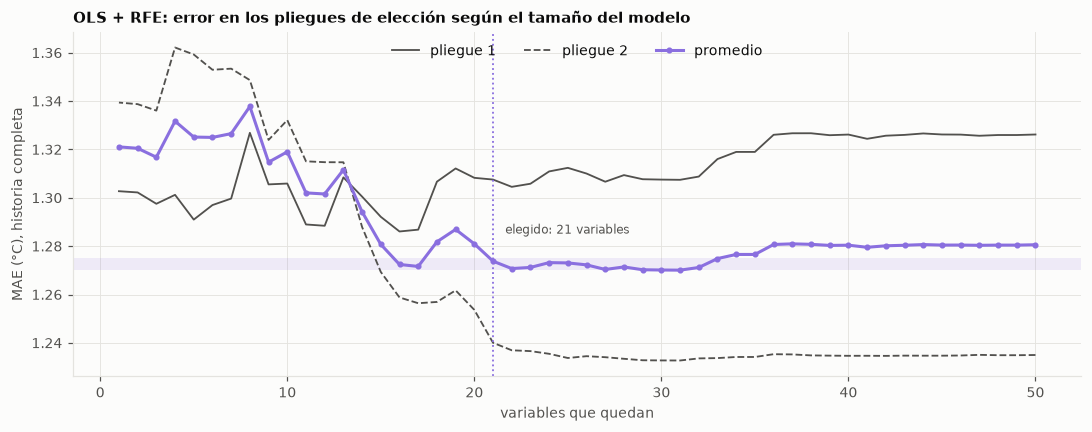

,MAE_pliegue_1,MAE_pliegue_2,delta_promedio,delta_max,cumple
n_variables,,,,,
1,1.3027,1.3394,0.0510,0.1067,False
2,1.3022,1.3387,0.0504,0.1060,False
3,1.2975,1.3361,0.0467,0.1034,False
4,1.3012,1.3622,0.0616,0.1294,False
5,1.2910,1.3593,0.0550,0.1266,False
6,1.2970,1.3530,0.0549,0.1202,False
7,1.2997,1.3534,0.0565,0.1207,False
8,1.3269,1.3487,0.0677,0.1160,False
9,1.3055,1.3239,0.0447,0.0912,False


In [2]:
pl = [c for c in CURVA.columns if c.startswith("MAE_pliegue_")]
prom = CURVA[pl].mean(axis=1)
fig, ax = plt.subplots(figsize=(10, 4))
for c, ls in zip(pl, ["-", "--"]):
    ax.plot(CURVA.index, CURVA[c], color=TXT2, lw=1.2, ls=ls, label=c.replace("MAE_pliegue_", "pliegue "))
ax.plot(prom.index, prom, color=COLOR["ols_rfe"], marker="o", ms=3, label="promedio")
ax.axhspan(prom.min(), prom.min() + ELEG["umbral_promedio_c"], color=COLOR["ols_rfe"], alpha=0.12, lw=0)
ax.axvline(ELEG["n_variables"], color=COLOR["ols_rfe"], ls=":", lw=1.2)
ax.annotate(f"elegido: {ELEG['n_variables']} variables", (ELEG["n_variables"], prom.loc[ELEG["n_variables"]]),
            xytext=(8, 18), textcoords="offset points", color=TXT2, fontsize=8)
ax.set(xlabel="variables que quedan", ylabel="MAE (°C), historia completa",
       title="OLS + RFE: error en los pliegues de elección según el tamaño del modelo")
ax.legend(loc="upper center", ncol=3)
plt.tight_layout(); plt.show()
display(CURVA.loc[sorted(CURVA.index)[:15], pl + ["delta_promedio", "delta_max", "cumple"]])

## 2. Qué variables sobreviven

Orden de eliminación: arriba las que salieron primero (menos peso), abajo las que más aguantan. El color es la familia;
el borde marca las elegidas.

findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


... (1,287 outputs left out)

findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


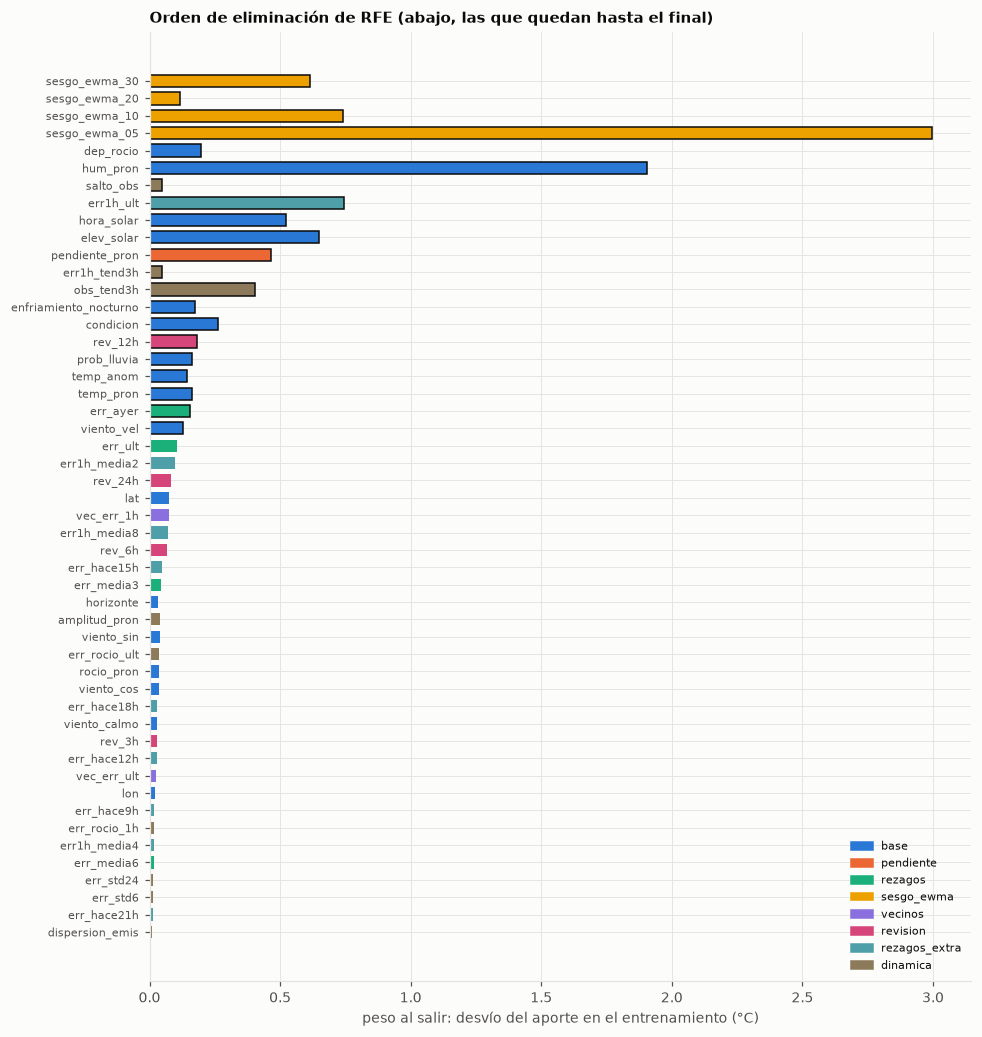

,variables elegidas,variables totales
base,10,17
sesgo_ewma,4,4
dinamica,3,9
rezagos,1,4
revision,1,4
rezagos_extra,1,9
pendiente,1,1
vecinos,0,2


In [3]:
o = ORDEN.iloc[::-1].reset_index(drop=True)
eleg = set(ELEG["variables"])
fig, ax = plt.subplots(figsize=(9, 0.17 * len(o) + 1))
ax.barh(o.sale, o.peso_sale_C, color=[COL_FAM[f] for f in o.familia],
        edgecolor=[TXT if v in eleg else "none" for v in o.sale], linewidth=1.0, height=0.7)
ax.invert_yaxis()
ax.tick_params(axis="y", labelsize=7)
ax.set(xlabel="peso al salir: desvío del aporte en el entrenamiento (°C)",
       title="Orden de eliminación de RFE (abajo, las que quedan hasta el final)")
ax.legend(handles=[Patch(color=c, label=f) for f, c in COL_FAM.items()], loc="lower right", fontsize=7)
plt.tight_layout(); plt.show()
fam = pd.Series(ELEG["familias"]).value_counts().rename("variables elegidas")
tot = ORDEN.familia.value_counts().rename("variables totales")
display(pd.concat([fam, tot], axis=1).fillna(0).astype(int).sort_values("variables elegidas", ascending=False))

## 3. El modelo final, leído como modelo explicativo

Peso de cada variable elegida en cada pliegue de reporte y si sus coeficientes cambian de signo entre pliegues
(OLS sin penalización puede ser inestable). Después, las curvas: cuánto suma cada valor de la variable a la corrección.

In [4]:
C = pd.read_csv(RFE / "coeficientes.csv", index_col=0)
pk = [c for c in C.columns if c.startswith("peso_pliegue_")]
ck = [c for c in C.columns if c.startswith("pliegue_")]
W = C.groupby("variable")[pk].first().loc[lambda d: d.index.isin(eleg)]
signo = C[C.variable.isin(eleg)].assign(cambia=lambda d: np.sign(d[ck]).nunique(axis=1) > 1).groupby("variable").cambia.mean()
W["peso_medio_C"] = W[pk].mean(axis=1)
W["coef_que_cambian_de_signo_%"] = 100 * signo
W["familia"] = W.index.map(ELEG["familias"])
display(W.sort_values("peso_medio_C", ascending=False))
print("columnas con |β| > 5 (°C por desvío): ", int((C[ck].abs() > 5).any(axis=1).sum()),
      "· |β| máximo:", round(float(C[ck].abs().max().max()), 2))

,peso_pliegue_3,peso_pliegue_4,peso_pliegue_5,peso_medio_C,coef_que_cambian_de_signo_%,familia
variable,,,,,,
sesgo_ewma_20,2.0385,1.5108,1.5236,1.6910,33.3333,sesgo_ewma
sesgo_ewma_10,1.7475,1.2453,1.2915,1.4281,33.3333,sesgo_ewma
dep_rocio,1.2034,1.2233,1.2045,1.2104,12.5000,base
hum_pron,1.0821,1.0185,1.0515,1.0507,0.0000,base
sesgo_ewma_30,1.1678,0.9595,0.9850,1.0375,33.3333,sesgo_ewma
hora_solar,0.4745,0.9619,0.5582,0.6649,16.6667,base
sesgo_ewma_05,0.6221,0.3830,0.3975,0.4675,33.3333,sesgo_ewma
elev_solar,0.2245,0.7358,0.3167,0.4257,0.0000,base
enfriamiento_nocturno,0.3172,0.3669,0.3680,0.3507,0.0000,base


columnas con |β| > 5 (°C por desvío):  0 · |β| máximo: 2.46


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


... (1,028 outputs left out)

findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


findfont: Font family 'Helvetica Neue' not found.


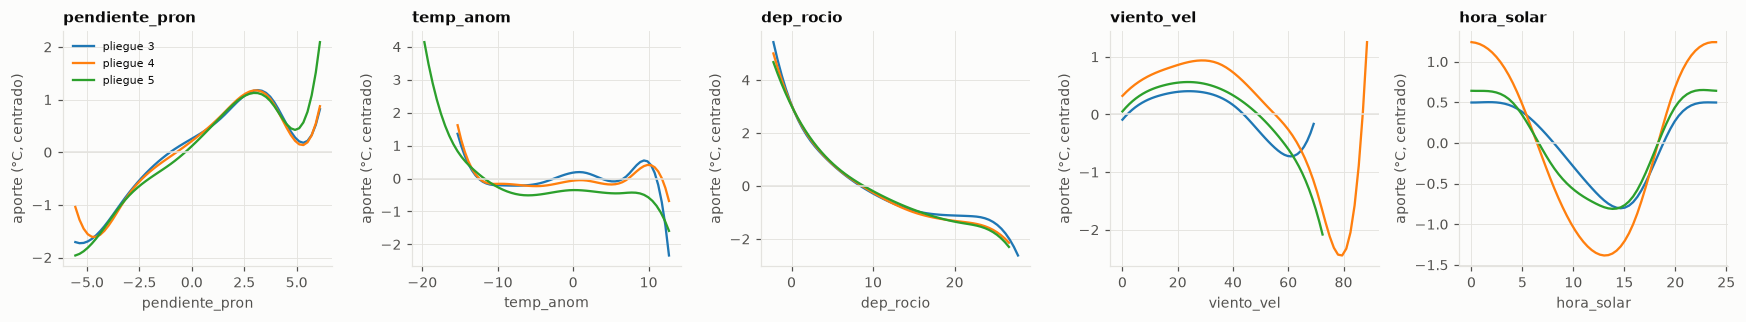

In [5]:
CV = pd.read_csv(RFE / "curvas.csv")
vs = list(CV.variable.unique())
if vs:
    fig, axs = plt.subplots(1, len(vs), figsize=(3.2 * len(vs), 3), squeeze=False)
    for ax, v in zip(axs[0], vs):
        for k, g in CV[CV.variable == v].groupby("pliegue"):
            ax.plot(g.x, g.aporte_C, lw=1.5, label=f"pliegue {k}")
        ax.axhline(0, color=GRILLA, lw=1)
        ax.set(title=v, xlabel=v, ylabel="aporte (°C, centrado)")
    axs[0][0].legend(fontsize=7)
    plt.tight_layout(); plt.show()
else:
    print("ninguna variable con curva sobrevivió")

## 4. Comparación con el Ridge y LightGBM (pliegues de reporte)

Recién acá se leen los resultados de los otros modelos (`data/resultados/`). Mismas filas de prueba y mismos baselines.

In [6]:
def mae(df, modelo, seg="todas"):
    x = df[(df.segmento == seg) & (df.modelo == modelo)].astype({"horizonte": str})
    return x.groupby("horizonte").apply(lambda g: np.average(g.MAE, weights=g.n), include_groups=False)

R_rfe = pd.read_csv(RFE / "por_pliegue.csv")
R_lin = pd.read_csv(RAIZ / "salidas" / "ridge" / "por_pliegue.csv")
R_gbm = pd.read_csv(RAIZ / "salidas" / "lgbm" / "por_pliegue.csv")
assert sorted(R_rfe.pliegue.unique()) == sorted(R_lin.pliegue.unique()) == sorted(R_gbm.pliegue.unique()), "pliegues distintos"
H = ["todos", "1", "3", "6", "12", "24", "48"]
for seg in ("todas", "completa", "incompleta"):
    T = pd.DataFrame({NOMBRE["B0"]: mae(R_rfe, "B0", seg), NOMBRE["B2"]: mae(R_rfe, "B2", seg),
                      NOMBRE["ols_rfe"]: mae(R_rfe, "ols_rfe", seg), NOMBRE["lineal"]: mae(R_lin, "lineal", seg),
                      NOMBRE["lgbm"]: mae(R_gbm, "lgbm", seg)}).reindex(H)
    print(f"MAE (°C), días con historia {seg}, pliegues {sorted(R_rfe.pliegue.unique())}")
    display(T)

MAE (°C), días con historia todas, pliegues [np.int64(3), np.int64(4), np.int64(5)]


,NWS crudo (B0),Estación × hora (B2),OLS + RFE,Ridge,LightGBM
horizonte,,,,,
todos,1.5413,1.4407,1.3687,1.3614,1.3105
1,1.3797,1.2936,1.1495,1.0625,1.0340
3,1.3996,1.3089,1.1858,1.1557,1.0941
6,1.4204,1.3250,1.2236,1.2202,1.1541
12,1.4629,1.3620,1.2768,1.2758,1.2116
24,1.5368,1.4300,1.3679,1.3645,1.3121
48,1.6853,1.5977,1.5420,1.5387,1.5173


MAE (°C), días con historia completa, pliegues [np.int64(3), np.int64(4), np.int64(5)]


,NWS crudo (B0),Estación × hora (B2),OLS + RFE,Ridge,LightGBM
horizonte,,,,,
todos,1.5189,1.4477,1.3878,1.3866,1.3329
1,1.3152,1.2669,1.1360,1.0519,1.0142
3,1.3380,1.2818,1.1761,1.1457,1.0776
6,1.3641,1.2987,1.2186,1.2143,1.1470
12,1.4253,1.3528,1.2821,1.2867,1.2223
24,1.5254,1.4482,1.3978,1.4002,1.3443
48,1.6916,1.6416,1.5950,1.6005,1.5722


MAE (°C), días con historia incompleta, pliegues [np.int64(3), np.int64(4), np.int64(5)]


,NWS crudo (B0),Estación × hora (B2),OLS + RFE,Ridge,LightGBM
horizonte,,,,,
todos,1.5614,1.4344,1.3515,1.3388,1.2903
1,1.4379,1.3176,1.1616,1.0719,1.0518
3,1.4549,1.3332,1.1946,1.1646,1.1088
6,1.4710,1.3487,1.2280,1.2254,1.1604
12,1.4968,1.3702,1.2720,1.2661,1.2019
24,1.5471,1.4136,1.3411,1.3325,1.2832
48,1.6801,1.5611,1.4977,1.4871,1.4715


### ¿La diferencia con el Ridge es real? (día como unidad)

D = MAE_OLS-RFE − MAE_otro por día de prueba. t pareado + bootstrap de 10 000 remuestreos (igual que `comparar_modelos.py`).

In [7]:
P = pd.read_csv(RFE / "por_dia.csv").merge(
    pd.read_csv(RES / "por_dia.csv")[["pliegue", "dia", "historia", "n", "B0", "B2", "lineal", "lgbm"]],
    on=["pliegue", "dia"], suffixes=("_rfe", ""),
)
assert (P.n_rfe == P.n).all(), "OLS-RFE y los otros modelos no evaluaron las mismas filas"
rng = np.random.default_rng(42)
filas = []
for otro in ("lineal", "lgbm", "B2"):
    for hist in ("todas", "completa", "incompleta"):
        x = P if hist == "todas" else P[P.historia == hist]
        d = (x.ols_rfe - x[otro]).to_numpy()
        boot = rng.choice(d, size=(10000, len(d))).mean(1)
        filas.append({"contra": NOMBRE[otro], "historia": hist, "días": len(d), "dif media °C": d.mean(),
                      "IC95 inf": np.percentile(boot, 2.5), "IC95 sup": np.percentile(boot, 97.5),
                      "p (t)": stats.ttest_1samp(d, 0).pvalue, "días que gana OLS-RFE": int((d < 0).sum())})
display(pd.DataFrame(filas))

,contra,historia,días,dif media °C,IC95 inf,IC95 sup,p (t),días que gana OLS-RFE
0,Ridge,todas,15,0.0076,0.0004,0.0145,0.0613,5
1,Ridge,completa,7,0.0016,-0.0097,0.0134,0.8058,4
2,Ridge,incompleta,8,0.0128,0.0054,0.0189,0.0097,1
3,LightGBM,todas,15,0.0587,0.0417,0.0763,0.0000,0
4,LightGBM,completa,7,0.0555,0.0358,0.0744,0.0023,0
5,LightGBM,incompleta,8,0.0614,0.0348,0.0915,0.0052,0
6,Estación × hora (B2),todas,15,-0.0723,-0.1045,-0.0446,0.0004,13
7,Estación × hora (B2),completa,7,-0.0602,-0.0897,-0.0283,0.0125,6
8,Estación × hora (B2),incompleta,8,-0.0830,-0.1357,-0.0398,0.0156,7


## 5. Para criticar

- **El orden sale de 2 pliegues.** Con otros días de elección el orden podría cambiar, sobre todo entre variables de
  peso parecido.
- **Variables redundantes se reparten el peso.** Si dos variables dicen lo mismo, cada una pesa poco y RFE puede sacar
  una primero aunque el par importe; la otra absorbe su efecto. Por eso el orden no es «importancia» en sentido causal.
- **OLS no encoge.** Las columnas colineales (bases spline, indicadores) se resuelven con la seudoinversa: la predicción
  es única, los coeficientes sueltos no. Se leen las curvas y los pesos por variable, no cada β.
- **El peso mira el entrenamiento, no la prueba.** Es RFE clásico: una variable puede pesar mucho y no ayudar fuera
  de la muestra. La curva (sección 1) es la que dice si sacarla empeora.
- **Comparación justa con el Ridge:** el Ridge eligió familias enteras con ablación; acá se eligen variables sueltas.
  Si OLS-RFE empata con menos variables, el modelo es más simple de explicar con el mismo error.